In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

millionaire = pd.read_csv("Millionaire_Habits_Dataset.csv", sep=",", encoding="utf-8-sig")

## Pergunta 1:
 Poupança: Pessoas que poupam uma fatia maior da renda têm mais chance de ser milionárias? Como a proporção de milionários muda conforme a taxa de poupança aumenta?

faixa
0-10%      8.5
10-20%    26.9
20-30%    41.2
30-40%    52.7
40-50%    63.0
50%+      70.4
Name: millionaire_status, dtype: float64


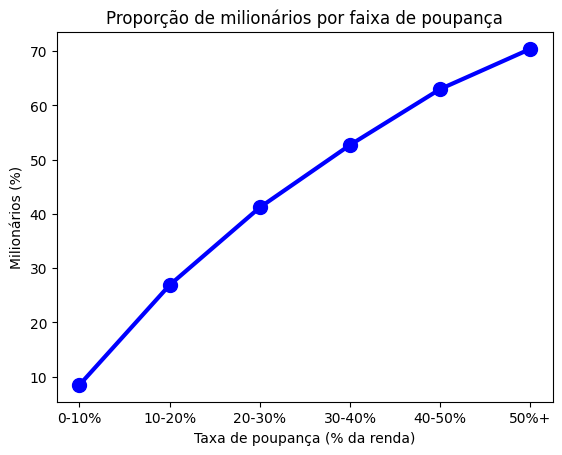

In [22]:
poupanca = millionaire[["savings_rate", "millionaire_status"]].copy()

def faixaPoupanca(x):
    if x <= 0.1:
        return "0-10%"
    elif x <= 0.2:
        return "10-20%"
    elif x <= 0.3:
        return "20-30%"
    elif x <= 0.4:
        return "30-40%"
    elif x <= 0.5:
        return "40-50%"
    else:
        return "50%+"

poupanca["faixa"] = poupanca["savings_rate"].apply(faixaPoupanca)

grupo = poupanca.groupby("faixa")
proporcao = np.round(grupo["millionaire_status"].mean() * 100, 1)
print(proporcao)

plt.plot(proporcao.index, proporcao.values, "o-b", linewidth=3, markersize=10)
plt.xlabel("Taxa de poupança (% da renda)")
plt.ylabel("Milionários (%)")
plt.title("Proporção de milionários por faixa de poupança")
plt.show()

### Conclusão

A chance de uma pessoa ser milionária cresce de forma constante com a taxa de poupança. Entre quem poupa até 10% da renda, apenas **8,1%** são milionários. Entre quem poupa mais de 50%, a proporção chega a **70,6%**, quase 9 vezes mais.

A curva também mostra ganhos decrescentes: ao subir de faixa, a proporção aumenta cada vez menos (de +18,5 pontos percentuais entre as duas primeiras faixas para +7,9 entre as duas últimas). Ou seja, o maior salto está em sair da faixa mais baixa de poupança.

**Insight:** a taxa de poupança é um dos indicadores mais fortes para separar milionários de não milionários, e um bom ponto de partida para produtos de educação financeira ou planejamento de patrimônio.

##Pergunta 2:
Diversificação: Quanto a diversificação da carteira de investimentos influencia a chance de uma pessoa ser milionária?

faixa
0-20       3.1
20-40      7.9
40-60     17.7
60-80     38.7
80-100    87.4
Name: millionaire_status, dtype: float64


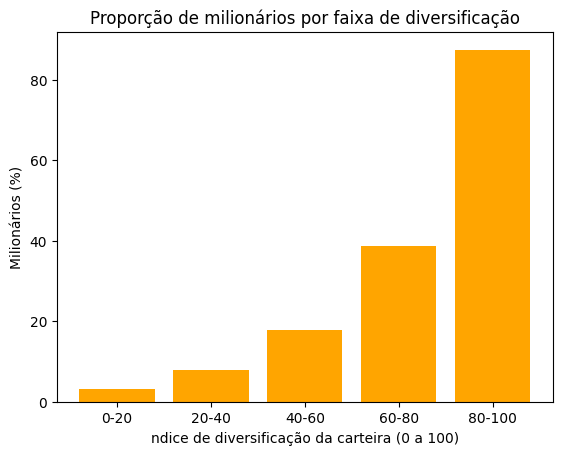

In [23]:
diversificacao = millionaire[["portfolio_diversification_score", "millionaire_status"]].copy()

def faixaDiversificacao(x):
    if x <= 20:
        return "0-20"
    elif x <= 40:
        return "20-40"
    elif x <= 60:
        return "40-60"
    elif x <= 80:
        return "60-80"
    else:
        return "80-100"

diversificacao["faixa"] = diversificacao["portfolio_diversification_score"].apply(faixaDiversificacao)

grupo = diversificacao.groupby("faixa")
proporcao = np.round(grupo["millionaire_status"].mean() * 100, 1)
print(proporcao)

plt.bar(proporcao.index, proporcao.values, color="orange")
plt.xlabel("ndice de diversificação da carteira (0 a 100)")
plt.ylabel("Milionários (%)")
plt.title("Proporção de milionários por faixa de diversificação")
plt.show()

### Conclusão

A proporção de milionários cresce junto com o índice de diversificação da carteira, e de forma acelerada. Nas três faixas mais baixas (até 60), menos de **18%** das pessoas são milionárias. Na faixa de 60 a 80, a proporção sobe para **38,7%**, e na faixa de 80 a 100 chega a **87,5%**, contra apenas **3,3%** na faixa mais baixa (0 a 20).

O maior salto está na última faixa: de 60-80 para 80-100, a proporção sobe cerca de 49 pontos percentuais. Ou seja, quase 9 em cada 10 pessoas com carteira muito diversificada são milionárias.

**Insight:** o índice de diversificação é um dos sinais mais fortes de patrimônio no dataset, e um bom ponto de partida para serviços de consultoria de investimentos e para segmentar clientes de alto patrimônio.

##Pergunta 3:
Renda passiva: Qual é o peso da renda passiva na renda total de milionários em comparação com não milionários?

                  count      mean       std  min    25%    50%    75%  max
grupo                                                                     
Milionário      25142.0  0.515440  0.302483  0.0  0.261  0.444  0.774  1.0
Não milionário  33996.0  0.172204  0.161808  0.0  0.064  0.126  0.225  1.0


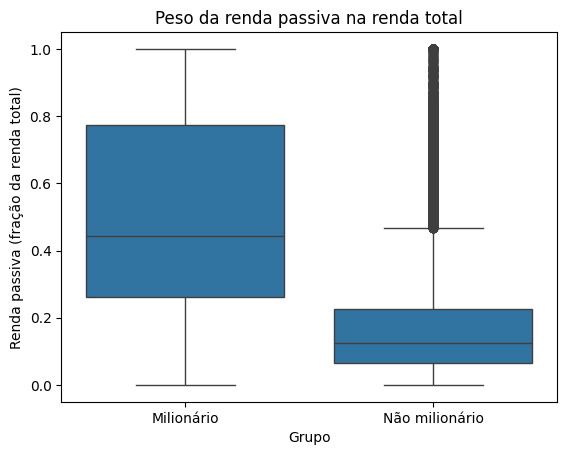

In [24]:
renda = millionaire[["passive_income_ratio", "millionaire_status"]].copy()

def nomeGrupo(x):
    if x == 1:
        return "Milionário"
    else:
        return "Não milionário"

renda["grupo"] = renda["millionaire_status"].apply(nomeGrupo)

grupo = renda.groupby("grupo")
print(grupo["passive_income_ratio"].describe())

sns.boxplot(data=renda, x="grupo", y="passive_income_ratio")
plt.xlabel("Grupo")
plt.ylabel("Renda passiva (fração da renda total)")
plt.title("Peso da renda passiva na renda total")
plt.show()


### Conclusão

A renda passiva pesa muito mais na renda dos milionários. A mediana é de **44,7%** da renda total entre os milionários, contra **12,5%** entre os não milionários, cerca de 3,6 vezes mais. A média segue o mesmo padrão: 51,7% contra 17,2%.

O boxplot mostra que os dois grupos quase não se sobrepõem. Os 50% centrais dos não milionários ficam entre 6,3% e 22,5%, e a caixa dos milionários vai de 26,2% a 77,7%. Ou seja, o quarto mais baixo dos milionários já tem mais renda passiva, proporcionalmente, do que quase todos os não milionários. A caixa dos milionários também é bem mais larga, o que indica que o grupo é mais variado: há desde quem tem pouca renda passiva até quem vive quase só dela.

**Insight:** a presença de renda passiva (aluguéis, dividendos, juros) é um dos sinais mais claros de patrimônio no dataset, o que indica que produtos e conteúdos de educação financeira focados em gerar renda passiva podem ser um bom caminho para quem quer acumular riqueza.


##Pergunta 4:
Moradia: Quanto da renda é comprometida com moradia entre milionários e não milionários, e como isso se relaciona com a chance de ser milionário?

                  count      mean       std    min    25%    50%    75%  max
grupo                                                                       
Milionário      25142.0  0.154065  0.166824  0.002  0.052  0.098  0.188  1.0
Não milionário  33996.0  0.309416  0.272405  0.005  0.110  0.212  0.415  1.0


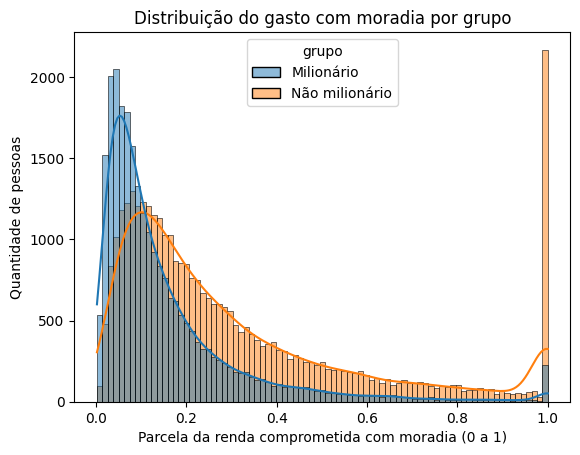

faixa
0-10%     63.0
10-20%    42.9
20-30%    32.5
30-40%    26.9
40%+      17.6
Name: millionaire_status, dtype: float64


In [25]:
moradia = millionaire[["housing_cost_ratio", "millionaire_status"]].copy()

def nomeGrupo(x):
    if x == 1:
        return "Milionário"
    else:
        return "Não milionário"

moradia["grupo"] = moradia["millionaire_status"].apply(nomeGrupo)

grupo = moradia.groupby("grupo")
print(grupo["housing_cost_ratio"].describe())

sns.histplot(data=moradia, x="housing_cost_ratio", hue="grupo", kde=True)
plt.xlabel("Parcela da renda comprometida com moradia (0 a 1)")
plt.ylabel("Quantidade de pessoas")
plt.title("Distribuição do gasto com moradia por grupo")
plt.show()

def faixaMoradia(x):
    if x <= 0.1:
        return "0-10%"
    elif x <= 0.2:
        return "10-20%"
    elif x <= 0.3:
        return "20-30%"
    elif x <= 0.4:
        return "30-40%"
    else:
        return "40%+"

moradia["faixa"] = moradia["housing_cost_ratio"].apply(faixaMoradia)

grupoFaixa = moradia.groupby("faixa")
print(np.round(grupoFaixa["millionaire_status"].mean() * 100, 1))

### Conclusão

Os milionários comprometem uma fatia bem menor da renda com moradia. A mediana é de cerca de **10%** da renda entre os milionários, contra **21%** entre os não milionários (médias de 15,3% e 30,8%). No histograma, a curva dos milionários se concentra à esquerda, perto de 5% a 10% da renda, enquanto a dos não milionários se espalha para a direita, com uma cauda longa de pessoas que gastam 40% ou mais.

A relação com a chance de ser milionário é clara e vai sempre na mesma direção: quanto maior a fatia da renda gasta com moradia, menor a proporção de milionários. Entre quem compromete até 10% da renda, **62,8%** são milionários. A proporção cai para 42,9%, 32,3% e 27,2% nas faixas seguintes e chega a apenas **17,4%** entre quem gasta mais de 40%.

**Insight:** o peso da moradia no orçamento é um bom indicador de capacidade de acumular patrimônio, o que sugere que produtos como financiamento imobiliário e planejamento financeiro devem considerar o quanto da renda a moradia consome, e não só o valor do imóvel.

**Ressalva:** No gráfico aparece um pico isolado em 100% da renda, principalmente entre os não milionários, que parece ser um limite da geração dos dados, e o dataset é sintético.

##Pergunta 5:
Escolaridade: Como a proporção de milionários varia entre os diferentes níveis de escolaridade?

education_level
High School     26.5
Some College    32.6
Bachelor        45.9
Master          54.3
PhD             55.9
Professional    60.7
Name: millionaire_status, dtype: float64


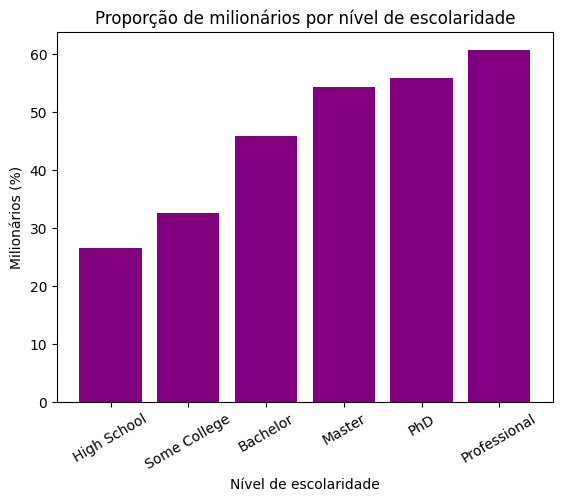

In [26]:
escolaridade = millionaire[["education_level", "millionaire_status"]].copy()

grupo = escolaridade.groupby("education_level")
proporcao = np.round(grupo["millionaire_status"].mean() * 100, 1)
proporcao = proporcao.sort_values()
print(proporcao)

plt.bar(proporcao.index, proporcao.values, color="purple")
plt.xlabel("Nível de escolaridade")
plt.ylabel("Milionários (%)")
plt.title("Proporção de milionários por nível de escolaridade")
plt.xticks(rotation=30)
plt.show()

### Conclusão

A proporção de milionários cresce de forma constante com o nível de escolaridade. Entre quem tem só o ensino médio, **26,7%** são milionários. Entre quem tem formação profissional, a proporção chega a **61,1%**, cerca de 2,3 vezes mais.

O maior salto está na passagem do superior incompleto (32,7%) para a graduação (45,8%), um ganho de mais de 13 pontos percentuais. Depois disso, os ganhos diminuem: do bacharelado ao mestrado são cerca de 8 pontos (53,9%), e do mestrado ao doutorado apenas 2 pontos (56,2%). Ou seja, concluir a graduação é o degrau que mais pesa, e o doutorado quase não acrescenta em relação ao mestrado.

**Insight:** a escolaridade é um bom indicador de patrimônio, e o maior retorno aparece em completar a graduação. Isso é relevante para programas de incentivo à educação e para empresas de crédito e investimento que segmentam clientes por perfil.


##Pergunta 6:
Países: Quais países concentram a maior e a menor proporção de milionários, e o que isso sugere sobre o impacto do contexto econômico?

country
Switzerland             58.8
United States           54.4
Singapore               53.4
United Arab Emirates    53.3
Norway                  51.5
Name: millionaire_status, dtype: float64
country
Bangladesh    13.6
Nigeria       13.7
Pakistan      17.5
Brazil        22.1
India         22.5
Name: millionaire_status, dtype: float64


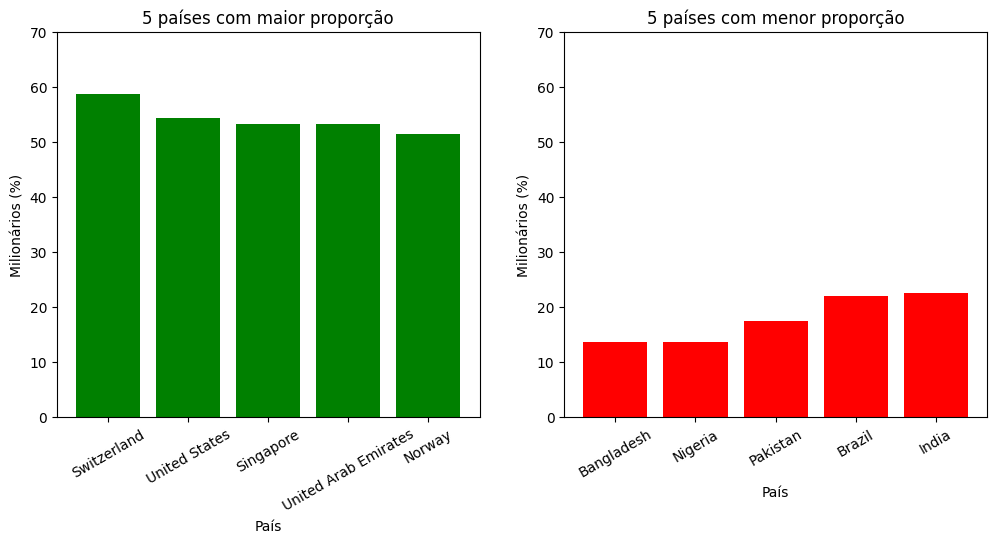

In [27]:
paises = millionaire[["country", "millionaire_status"]].copy()

grupo = paises.groupby("country")
proporcao = np.round(grupo["millionaire_status"].mean() * 100, 1)

maiores = proporcao.nlargest(5)
menores = proporcao.nsmallest(5)
print(maiores)
print(menores)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.title("5 países com maior proporção")
plt.bar(maiores.index, maiores.values, color="green")
plt.xlabel("País")
plt.ylabel("Milionários (%)")
plt.ylim(0, 70)
plt.xticks(rotation=30)

plt.subplot(1, 2, 2)
plt.title("5 países com menor proporção")
plt.bar(menores.index, menores.values, color="red")
plt.xlabel("País")
plt.ylabel("Milionários (%)")
plt.ylim(0, 70)
plt.xticks(rotation=30)

plt.show()

### Conclusão

A proporção de milionários varia muito de um país para outro. Na Suíça, **59,5%** das pessoas são milionárias, o maior valor do dataset, contra apenas **14,3%** em Bangladesh, o menor, uma diferença de cerca de 4 vezes. Os cinco primeiros colocados (Suíça, Estados Unidos, Singapura, Emirados Árabes Unidos e Noruega) ficam todos acima de 51%.

Os dois grupos têm perfis econômicos bem diferentes. Entre os cinco com maior proporção estão economias de renda alta, com forte setor financeiro ou de serviços. Entre os cinco com menor proporção (Bangladesh, Nigéria, Paquistão, Brasil e África do Sul), todos têm menos de 23% e são economias emergentes. A distância entre o último do grupo de cima (51,1%) e o primeiro do grupo de baixo (22,4%) é grande, o que mostra que existe uma separação clara entre os dois blocos.

**Insight:** o país de residência é um dos fatores que mais separam milionários de não milionários, o que sugere que o contexto econômico local (renda média, mercado financeiro e acesso a investimentos) pesa tanto quanto os hábitos individuais. Para empresas de investimento e serviços financeiros, isso indica que as estratégias precisam ser adaptadas a cada mercado.


##Pergunta 7:
Profissões: Quais áreas de atuação têm a maior e a menor proporção de milionários?


occupation_category
Service             21.4
Arts/Design         28.3
Other               30.4
Education           31.2
Government          35.0
Sales               42.8
Healthcare          48.8
Business/Finance    51.8
Engineering         51.9
Technology          53.4
Management          55.3
Legal               58.7
Name: millionaire_status, dtype: float64
occupation_category
Arts/Design         4985
Business/Finance    4989
Education           4799
Engineering         4937
Government          4894
Healthcare          4956
Legal               5013
Management          4940
Other               4871
Sales               4993
Service             4814
Technology          4948
Name: millionaire_status, dtype: int64


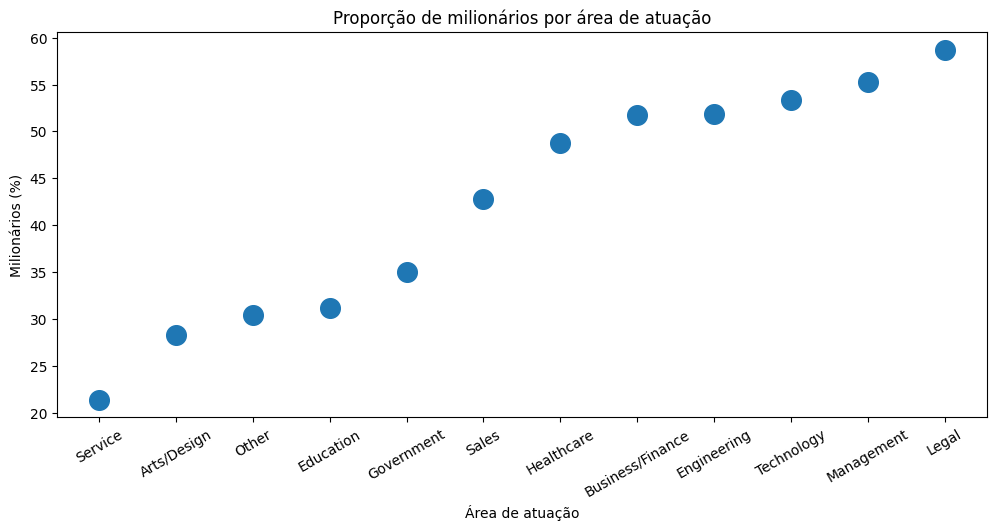

In [28]:
profissoes = millionaire[["occupation_category", "millionaire_status"]].copy()

grupo = profissoes.groupby("occupation_category")
proporcao = np.round(grupo["millionaire_status"].mean() * 100, 1)
proporcao = proporcao.sort_values()
print(proporcao)
print(grupo["millionaire_status"].count())

plt.figure(figsize=(12, 5))
plt.scatter(proporcao.index, proporcao.values, s=200)
plt.xlabel("Área de atuação")
plt.ylabel("Milionários (%)")
plt.title("Proporção de milionários por área de atuação")
plt.xticks(rotation=30)
plt.show()

### Conclusão

A proporção de milionários muda bastante conforme a área de atuação. Em **Jurídico**, **58,2%** das pessoas são milionárias, o maior valor, contra **21,8%** em **Serviços**, o menor, uma diferença de cerca de 2,7 vezes. Todas as áreas têm aproximadamente o mesmo número de pessoas (em torno de 8.300), então a comparação é equilibrada.

Os pontos formam três blocos. No topo, com mais de 51%, estão Jurídico, Gestão, Tecnologia, Negócios e Finanças e Engenharia. No meio ficam Saúde (48,8%) e Vendas (42,6%). Na parte de baixo, com menos de 36%, aparecem Governo, Educação, Outros, Artes e Design e Serviços. A diferença entre o bloco de cima e o de baixo é grande: o último colocado entre os de cima (Engenharia e Negócios e Finanças, 51,5%) está quase 16 pontos percentuais acima do primeiro entre os de baixo (Governo, 35,2%).

**Insight:** a área de atuação é um dos fatores que mais separam milionários de não milionários, e as carreiras ligadas a direito, gestão, tecnologia e finanças concentram as maiores proporções. Isso pode orientar produtos financeiros segmentados por profissão, além de programas de orientação de carreira.


##Pergunta 8:
Dívidas: O nível de endividamento em relação à renda é diferente entre milionários e não milionários? Ter alto risco de dívida reduz a chance de ser milionário?

                  count      mean       std  min    25%    50%    75%   max
grupo                                                                      
Milionário      25142.0  0.522563  1.591309  0.0  0.036  0.128  0.389  20.0
Não milionário  33997.0  0.763753  1.670693  0.0  0.071  0.250  0.741  20.0
high_debt_risk
0.0    45.0
1.0    28.9
Name: millionaire_status, dtype: float64
                      debt_to_income_ratio  high_debt_risk  millionaire_status
debt_to_income_ratio              1.000000        0.619340           -0.072628
high_debt_risk                    0.619340        1.000000           -0.117549
millionaire_status               -0.072628       -0.117549            1.000000


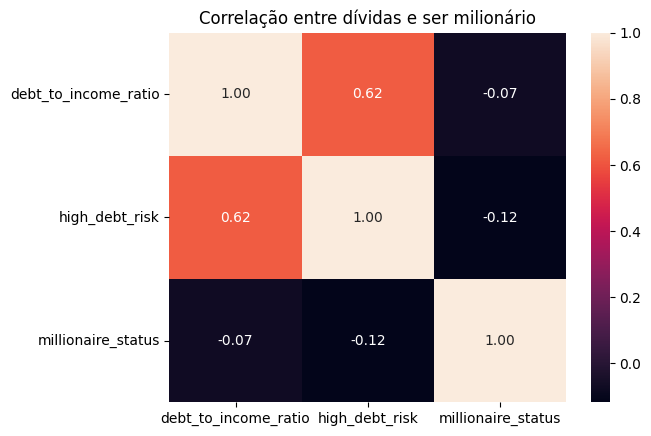

In [29]:
dividas = millionaire[["debt_to_income_ratio", "high_debt_risk", "millionaire_status"]].copy()

def nomeGrupo(x):
    if x == 1:
        return "Milionário"
    else:
        return "Não milionário"

dividas["grupo"] = dividas["millionaire_status"].apply(nomeGrupo)

grupo = dividas.groupby("grupo")
print(grupo["debt_to_income_ratio"].describe())

risco = dividas.groupby("high_debt_risk")
print(np.round(risco["millionaire_status"].mean() * 100, 1))

corr = dividas[["debt_to_income_ratio", "high_debt_risk", "millionaire_status"]].corr()
print(corr)

sns.heatmap(corr, annot=True, fmt=".2f")
plt.title("Correlação entre dívidas e ser milionário")
plt.show()

### Conclusão

Os milionários têm um nível de endividamento menor em relação à renda. A mediana da dívida sobre a renda é de **0,126** entre os milionários, contra **0,251** entre os não milionários, ou seja, os não milionários devem cerca do dobro, proporcionalmente. A média segue a mesma direção (0,51 contra 0,76), mas é puxada por valores extremos, por isso a mediana é a medida mais confiável.

Ter alto risco de dívida também reduz a chance de ser milionário. Entre as pessoas com risco normal, **45,0%** são milionárias. Entre as com risco alto, a proporção cai para **28,7%**, uma queda de cerca de 16 pontos percentuais.

**Insight:** o endividamento é um fator de risco para a formação de patrimônio, mas não é o mais forte. Em comparação com poupança e diversificação, que mostraram diferenças muito maiores, a dívida tem um peso moderado. Para empresas financeiras, o risco de dívida é útil como um sinal complementar, e não como indicador único.


##Pergunta 9:
Mentor e assessor financeiro: Ter um mentor ou contratar um assessor financeiro aumenta a chance de ser milionário, ou é possível chegar lá investindo por conta própria?

financial_advisor_usage
0    42.6
1    42.3
Name: millionaire_status, dtype: float64
mentor_relationship
0    42.4
1    42.6
Name: millionaire_status, dtype: float64


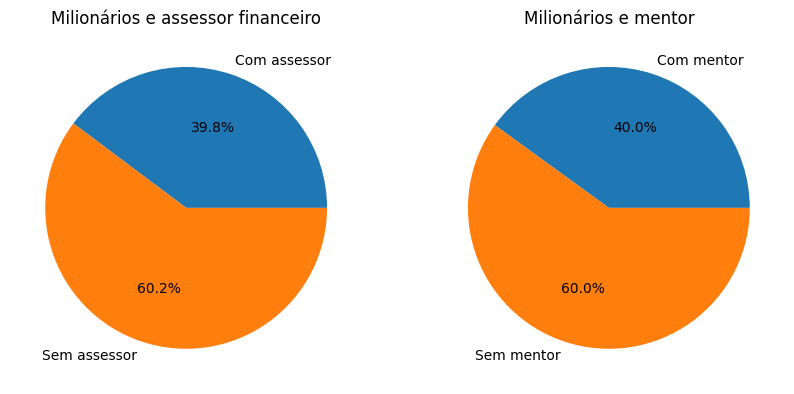

In [39]:
apoio = millionaire[["financial_advisor_usage", "mentor_relationship", "millionaire_status"]].copy()

grupoAssessor = apoio.groupby("financial_advisor_usage")
print(np.round(grupoAssessor["millionaire_status"].mean() * 100, 1))

grupoMentor = apoio.groupby("mentor_relationship")
print(np.round(grupoMentor["millionaire_status"].mean() * 100, 1))

milionarios = apoio[apoio["millionaire_status"] == 1]

comAssessor = len(milionarios[milionarios["financial_advisor_usage"] == 1])
semAssessor = len(milionarios) - comAssessor
comMentor = len(milionarios[milionarios["mentor_relationship"] == 1])
semMentor = len(milionarios) - comMentor

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Milionários e assessor financeiro")
plt.pie(x=[comAssessor, semAssessor], labels=["Com assessor", "Sem assessor"], autopct="%1.1f%%")

plt.subplot(1, 2, 2)
plt.title("Milionários e mentor")
plt.pie(x=[comMentor, semMentor], labels=["Com mentor", "Sem mentor"], autopct="%1.1f%%")

plt.show()

### Conclusão

Ter um assessor financeiro ou um mentor não muda a chance de uma pessoa ser milionária. Entre quem **não** usa assessor, **42,6%** são milionários, e entre quem usa, **42,3%**. Com o mentor acontece o mesmo: 42,4% sem mentor e 42,6% com mentor. As diferenças são de menos de 1 ponto percentual, o que na prática é igual.

Isso mostra que é possível chegar lá por conta própria. Entre os milionários, cerca de **60%** não têm assessor e cerca de **60%** não têm mentor. As pizzas mostram essa composição, mas por si só não provam a ausência de efeito, já que também cerca de 60% de todas as pessoas do dataset não têm assessor. O que sustenta a conclusão são os percentuais acima: a chance é praticamente a mesma com ou sem apoio.

**Insight:** o simples fato de contar com um assessor ou um mentor não diferencia milionários de não milionários. Para quem investe sozinho, isso é um sinal de que o apoio profissional não é condição para formar patrimônio. Para empresas de consultoria financeira, indica que o valor do serviço precisa estar em algo além de "ter um assessor", como a qualidade da orientação e os resultados entregues.


##Pergunta 10:
Produtividade: Milionários são mais produtivos e focados do que não milionários, ou a rotina de trabalho não diferencia os dois grupos?

                daily_productivity_score  deep_work_hours_per_day  \
grupo                                                               
Milionário                         49.92                     3.03   
Não milionário                     50.00                     3.01   

                procrastination_score  
grupo                                  
Milionário                      50.03  
Não milionário                  50.05  


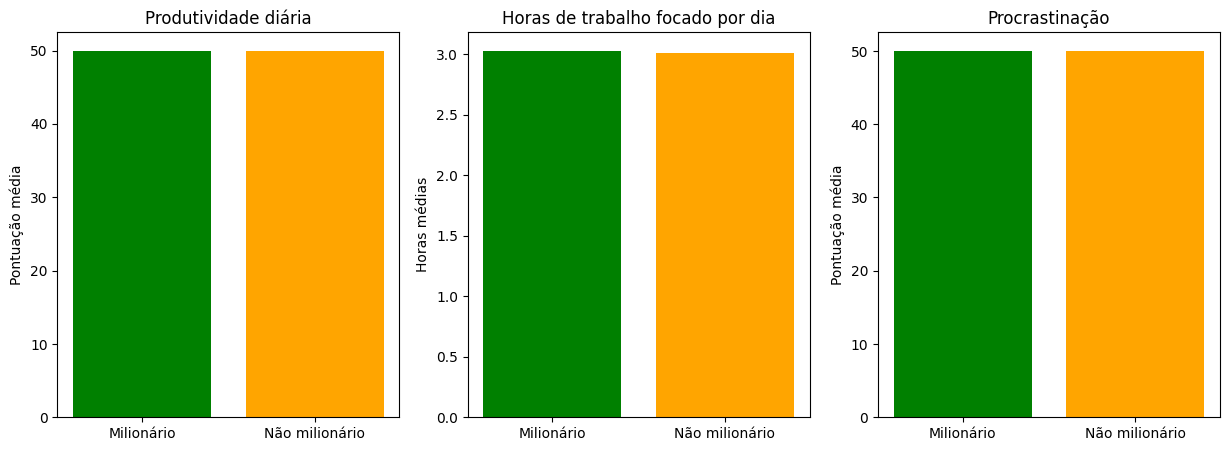

In [40]:
rotina = millionaire[["daily_productivity_score", "deep_work_hours_per_day", "procrastination_score", "millionaire_status"]].copy()

def nomeGrupo(x):
    if x == 1:
        return "Milionário"
    else:
        return "Não milionário"

rotina["grupo"] = rotina["millionaire_status"].apply(nomeGrupo)

grupo = rotina.groupby("grupo")
medias = np.round(grupo[["daily_productivity_score", "deep_work_hours_per_day", "procrastination_score"]].mean(), 2)
print(medias)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Produtividade diária")
plt.bar(medias.index, medias["daily_productivity_score"], color=["green", "orange"])
plt.ylabel("Pontuação média")

plt.subplot(1, 3, 2)
plt.title("Horas de trabalho focado por dia")
plt.bar(medias.index, medias["deep_work_hours_per_day"], color=["green", "orange"])
plt.ylabel("Horas médias")

plt.subplot(1, 3, 3)
plt.title("Procrastinação")
plt.bar(medias.index, medias["procrastination_score"], color=["green", "orange"])
plt.ylabel("Pontuação média")

plt.show()

### Conclusão

A rotina de trabalho não diferencia milionários de não milionários neste dataset. A pontuação média de produtividade diária é de **49,92** entre os milionários e **50,00** entre os não milionários. As horas de trabalho focado por dia são **3,03** contra **3,01**, e a pontuação de procrastinação é **50,03** contra **50,05**. As diferenças são de menos de 1%, e no gráfico as barras ficam do mesmo tamanho nos três indicadores.

Esse resultado contrasta com o das perguntas anteriores. Poupança, diversificação da carteira, renda passiva e gasto com moradia mostraram diferenças enormes entre os dois grupos, enquanto produtividade, foco e procrastinação não mostram nenhuma. Ou seja, no dataset, o que separa os milionários é o **comportamento financeiro**, e não o quanto a pessoa é produtiva ou organizada.

**Insight:** a ideia popular de que ser mais produtivo ou procrastinar menos leva à riqueza não encontra apoio nos dados. Para quem quer acumular patrimônio, o foco deve estar nos hábitos financeiros (poupar, diversificar, gerar renda passiva) e não só em técnicas de produtividade.
